# 1. Data Inspection & Cleaning
Cleaned missing `Color` values by category mode, standardized column names, engineered `revenue`, `discount_value`, `discount_pct`, and `price_group` tiers.


In [1]:
print(f'Cleaned Dataset Shape: {df.shape[0]:,} rows x {df.shape[1]} columns')
print('\nMissing Values After Cleaning:\n', df.isnull().sum()[df.isnull().sum() > 0].to_string())
print('\nNumeric Summary:\n', df[['listprice', 'unitprice', 'orderqty', 'revenue', 'discount_pct']].describe().round(2).to_string())
print('\nSample Rows:\n', df[['customer', 'region', 'business_segment', 'category', 'salesdate', 'orderqty', 'revenue']].head().to_string())


Cleaned Dataset Shape: 60,919 rows x 25 columns

Missing Values After Cleaning:
 days_since_last_order    633

Numeric Summary:
        listprice  unitprice  orderqty   revenue  discount_pct
count   60919.00   60919.00  60919.00  60919.00      60919.00
mean      771.32     444.28      3.52   1329.88         41.71
std       897.98     519.85      3.03   2140.47          4.02
min         2.29       1.33      1.00      1.37         26.00
25%        59.99      34.93      2.00    127.80         40.00
50%       364.09     209.26      3.00    461.69         40.00
75%      1120.49     672.29      4.00   1472.30         42.30
max      3578.27    2146.96     44.00  30993.04         80.00

Sample Rows:
        customer         region business_segment    category  salesdate  orderqty  revenue
0  A Bike Store  North America            Bikes  Road Bikes 2018-08-21         1  2146.96
1  A Bike Store  North America            Bikes  Road Bikes 2018-08-25         1   419.46
2  A Bike Store  North Ameri

# 2. Revenue, Discount & Business Segment Analysis


Total Revenue: 81014827.02
Total List Revenue: 141077294.55
Total Discount Given: 60062467.53
Weighted Avg Discount %: 42.57

--- Business Segment Summary ---
                   orders  units      revenue  avg_discount_pct  revenue_share_pct
business_segment                                                                 
Bikes              24826  75063  66827511.81             42.52              82.49
Components         18698  49044  11807764.77             41.26              14.57
Clothing           12293  64569   1801581.16             40.89               2.22
Accessories         5102  25840    577969.28             41.41               0.71


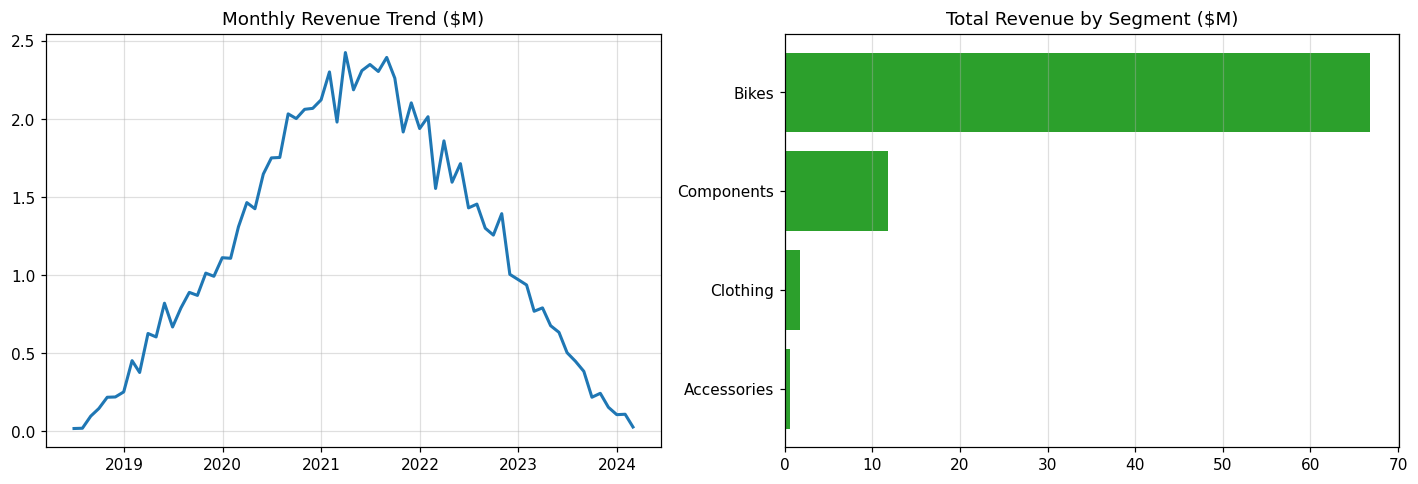

In [2]:
print('Total Revenue:', round(df['revenue'].sum(), 2))
print('Total List Revenue:', round(df['list_revenue'].sum(), 2))
print('Total Discount Given:', round(df['discount_value'].sum(), 2))
print('Weighted Avg Discount %:', round((df['discount_value'].sum() / df['list_revenue'].sum()) * 100, 2))
print('\n--- Business Segment Summary ---\n', seg.round(2).to_string())
monthly = df.set_index('salesdate').resample('ME')['revenue'].sum()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(monthly.index, monthly.values/1e6, color='#1f77b4', lw=2); ax[0].set_title('Monthly Revenue Trend ($M)'); ax[0].grid(True, alpha=0.4)
sr = seg['revenue'].sort_values()/1e6
ax[1].barh(sr.index, sr.values, color='#2ca02c'); ax[1].set_title('Total Revenue by Segment ($M)'); ax[1].grid(True, axis='x', alpha=0.4)
plt.tight_layout(); plt.show()


# 3. Geographic & Category Performance


--- Geographic & Market Breakdown ---
                                              orders  units      revenue  discount_val     list_rev  weighted_disc_pct
region        subregion      market                                                                                  
North America United States  Southwest        13379  46840  18597946.59   13981533.41  32579480.00              42.92
              Canada         Canada           11444  41761  14463206.56   10807346.18  25270552.74              42.77
              United States  Northwest         7872  27783  12523013.78    9240900.24  21763914.02              42.46
                             Central           5812  19473   7932816.17    5781174.98  13713991.15              42.16
                             Southeast         5937  18836   7908283.37    5836176.12  13744459.49              42.46
                             Northeast         5809  19816   6956641.47    5184279.93  12140921.40              42.70
Europe        Fra

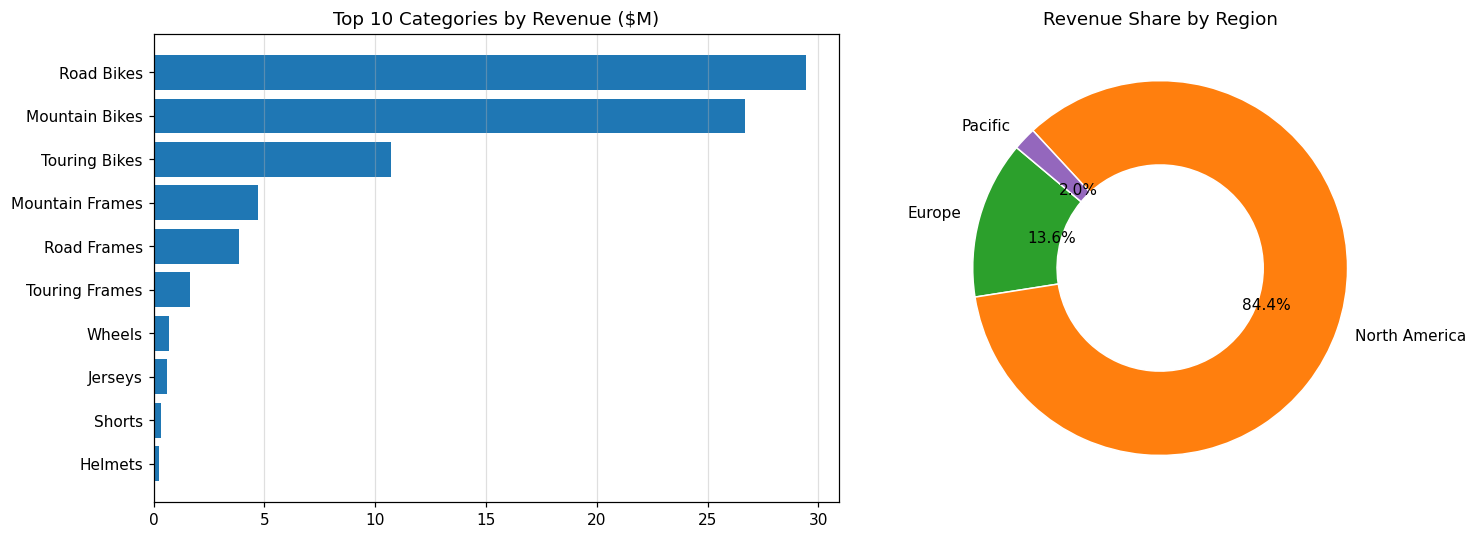

In [3]:
print('--- Geographic & Market Breakdown ---\n', geo.sort_values('revenue', ascending=False).round(2).to_string())
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
top_cat = df.groupby('category')['revenue'].sum().sort_values().tail(10)/1e6
ax[0].barh(top_cat.index, top_cat.values, color='#1f77b4'); ax[0].set_title('Top 10 Categories by Revenue ($M)'); ax[0].grid(True, axis='x', alpha=0.4)
reg_rev = df.groupby('region')['revenue'].sum()
ax[1].pie(reg_rev.values, labels=reg_rev.index, autopct='%1.1f%%', startangle=140, colors=['#2ca02c', '#ff7f0e', '#9467bd'], wedgeprops={'width': 0.45, 'edgecolor': 'white'})
ax[1].set_title('Revenue Share by Region'); plt.tight_layout(); plt.show()


# 4. Annual Segment Trends & Discount vs. Price Tier Impact


--- Annual Revenue by Segment ($M) ---
 business_segment  Accessories  Bikes  Clothing  Components
order_year                                                
2018                     0.00   0.91      0.01        0.06
2019                     0.04   7.74      0.18        1.27
2020                     0.15  16.82      0.52        3.26
2021                     0.19  21.65      0.62        4.01
2022                     0.16  14.46      0.39        2.55
2023                     0.04   5.12      0.08        0.64
2024                     0.00   0.13      0.00        0.01


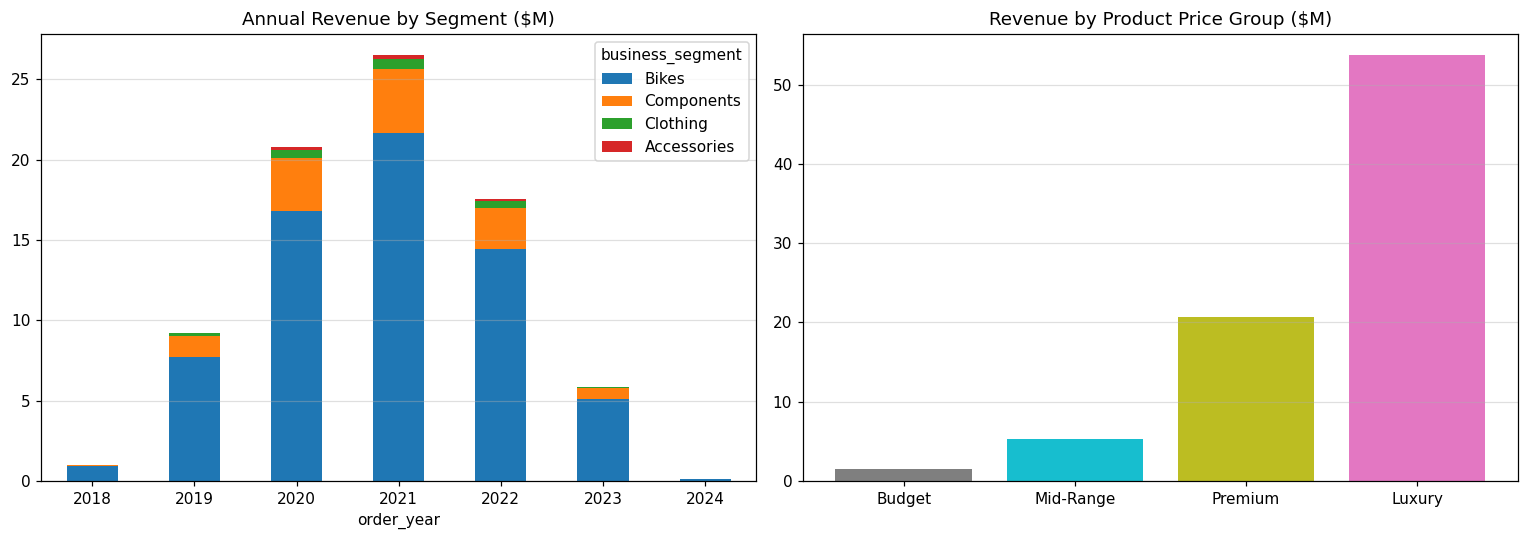

In [4]:
yearly_seg = df.pivot_table(index='order_year', columns='business_segment', values='revenue', aggfunc='sum', fill_value=0)/1e6
print('--- Annual Revenue by Segment ($M) ---\n', yearly_seg.round(2).to_string())
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
yearly_seg[['Bikes', 'Components', 'Clothing', 'Accessories']].plot(kind='bar', stacked=True, ax=ax[0], color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'])
ax[0].set_title('Annual Revenue by Segment ($M)'); ax[0].tick_params(axis='x', rotation=0); ax[0].grid(True, axis='y', alpha=0.4)
tier_rev = df.groupby('price_group', observed=False)['revenue'].sum().reindex(['Budget', 'Mid-Range', 'Premium', 'Luxury'])/1e6
ax[1].bar(tier_rev.index, tier_rev.values, color=['#7f7f7f', '#17becf', '#bcbd22', '#e377c2'])
ax[1].set_title('Revenue by Product Price Group ($M)'); ax[1].grid(True, axis='y', alpha=0.4); plt.tight_layout(); plt.show()


# 5. RFM Customer Segmentation & 80/20 Pareto Analysis


--- RFM Tier Summary ---
            customers  avg_revenue  total_revenue
tier                                            
Champions        214    304486.84    65160183.30
Loyal            115    100883.40    11601591.09
Potential        109     29290.68     3192684.27
At Risk          195      5437.79     1060368.36

--- Top 10 Customers by Revenue ---
                              customer    revenue  cum_rev_pct  cum_cust_pct
0                    Brakes and Gears  882273.53         1.09          0.16
1           Vigorous Exercise Company  860142.25         2.15          0.32
2           Excellent Riding Supplies  853848.29         3.20          0.47
3             Totes & Baskets Company  817125.03         4.21          0.63
4                         Retail Mall  803767.27         5.21          0.79
5               Corner Bicycle Supply  787806.32         6.18          0.95
6             Outdoor Equipment Store  751629.56         7.11          1.11
7  Thorough Parts and Repair Servi

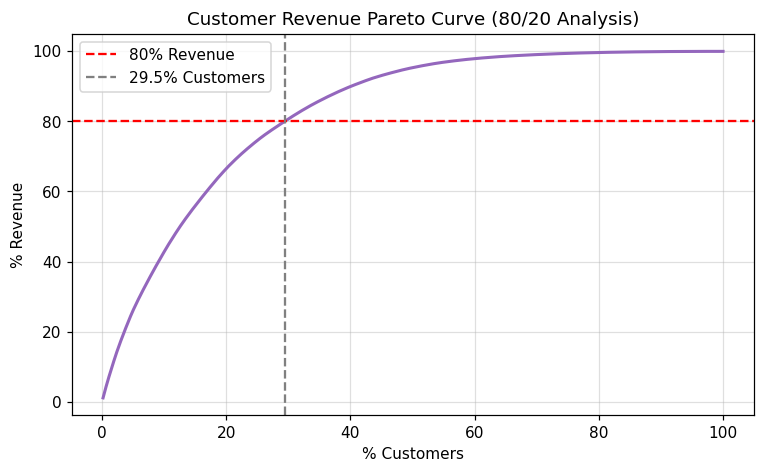

In [5]:
print('--- RFM Tier Summary ---\n', rfm_summary.round(2).to_string())
print('\n--- Top 10 Customers by Revenue ---\n', cust_rev.head(10).round(2).to_string())
plt.figure(figsize=(8, 4.5))
plt.plot(cust_rev['cum_cust_pct'], cust_rev['cum_rev_pct'], color='#9467bd', lw=2)
plt.axhline(80, color='red', ls='--', label='80% Revenue'); plt.axvline(29.5, color='gray', ls='--', label='29.5% Customers')
plt.title('Customer Revenue Pareto Curve (80/20 Analysis)'); plt.xlabel('% Customers'); plt.ylabel('% Revenue'); plt.legend(); plt.grid(True, alpha=0.4); plt.show()


# 6. Annual Customer Cohort Retention


--- Annual Cohort Retention (%) ---
 cohort_index      0     1     2      3     4     5     6
cohort_year                                             
2018          100.0  98.1  98.7  100.0  99.4  93.7  23.9
2019          100.0  94.7  94.7   92.1  68.0   1.8   0.0
2020          100.0  93.1  92.2   68.6   0.0   0.0   0.0
2021          100.0  56.7  30.0    0.0   0.0   0.0   0.0
2022          100.0  18.2   0.0    0.0   0.0   0.0   0.0
2023          100.0   0.0   0.0    0.0   0.0   0.0   0.0


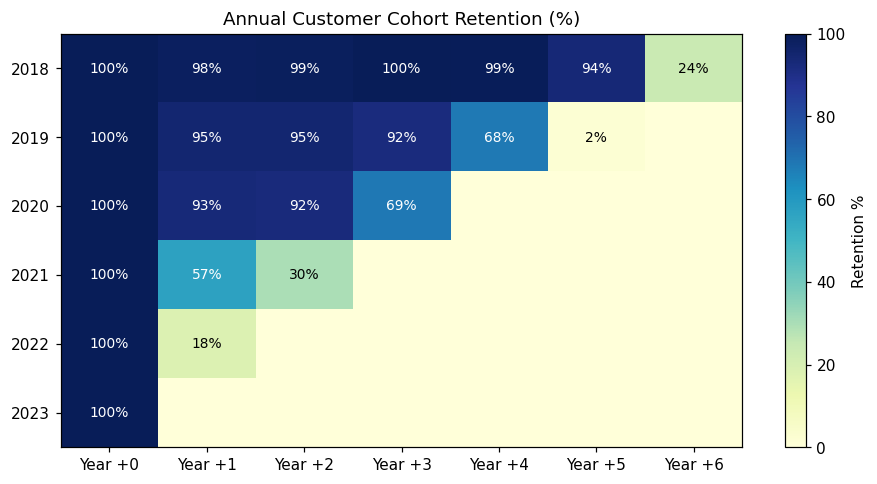

In [6]:
print('--- Annual Cohort Retention (%) ---\n', retention_pct.to_string())
plt.figure(figsize=(8.5, 4.5))
im = plt.imshow(retention_pct.values, cmap='YlGnBu', aspect='auto', vmin=0, vmax=100)
plt.xticks(range(retention_pct.shape[1]), [f'Year +{i}' for i in retention_pct.columns])
plt.yticks(range(retention_pct.shape[0]), retention_pct.index)
for i in range(retention_pct.shape[0]):
    for j in range(retention_pct.shape[1]):
        v = retention_pct.iloc[i, j]
        if v > 0: plt.text(j, i, f'{v:.0f}%', ha='center', va='center', color='white' if v > 55 else 'black', fontsize=9)
plt.title('Annual Customer Cohort Retention (%)'); plt.colorbar(im, label='Retention %'); plt.tight_layout(); plt.show()


# 7. Machine Learning: K-Means Clustering, Churn Classifier & OrderQty Regressor


--- K-Means Customer Clusters ---
          recency  frequency  monetary  avg_discount_pct  avg_order_qty
Cluster                                                               
0          873.8       10.6    9677.1              42.2            1.7
1          318.7       62.6   68516.4              41.0            2.5
2          188.3      289.0  425055.0              41.7            3.9
3          224.2       38.2   51061.0              44.3            1.9

Churn Risk Random Forest ROC-AUC: 0.834
OrderQty Regressor MAE: 1.550 | R2: 0.587


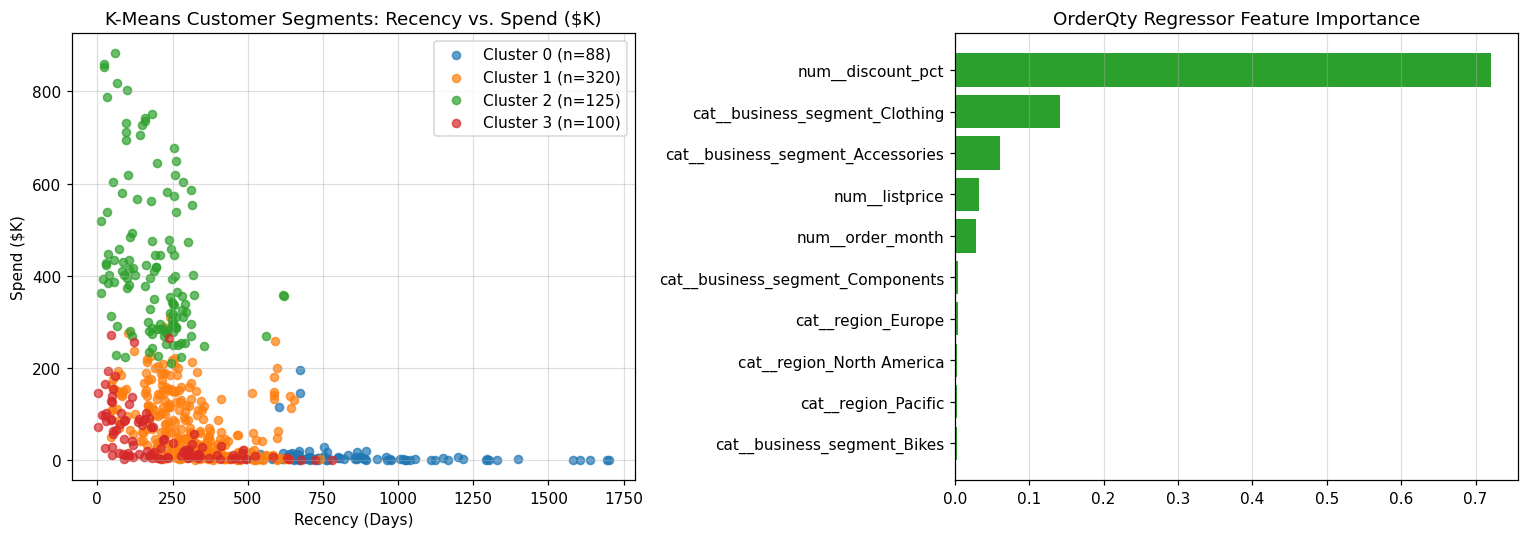

In [7]:
print('--- K-Means Customer Clusters ---\n', cust_features.groupby('Cluster').mean().round(1).to_string())
print(f'\nChurn Risk Random Forest ROC-AUC: {roc_auc_score(y_test, clf.predict_proba(X_test)[:, 1]):.3f}')
print(f'OrderQty Regressor MAE: {mean_absolute_error(yr_test, yr_pred):.3f} | R2: {r2_score(yr_test, yr_pred):.3f}')
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for cid, col in enumerate(['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']):
    s = cust_features[cust_features['Cluster'] == cid]
    ax[0].scatter(s['recency'], s['monetary']/1e3, label=f'Cluster {cid} (n={len(s)})', alpha=0.7, s=28, color=col)
ax[0].set_title('K-Means Customer Segments: Recency vs. Spend ($K)'); ax[0].set_xlabel('Recency (Days)'); ax[0].set_ylabel('Spend ($K)'); ax[0].legend(); ax[0].grid(True, alpha=0.4)
fn = reg_pipe.named_steps['prep'].get_feature_names_out()
imp = reg_pipe.named_steps['rf'].feature_importances_; idx = np.argsort(imp)
ax[1].barh(fn[idx], imp[idx], color='#2ca02c'); ax[1].set_title('OrderQty Regressor Feature Importance'); ax[1].grid(True, axis='x', alpha=0.4)
plt.tight_layout(); plt.show()
